# Diffrax batching, precision, and device study

## Abstract

This experiment measures a production-shaped Diffrax workload across CPU and
GPU, two adaptive-controller batching policies, and three floating-point
tolerance configurations. Each solve integrates 10,000 driven-pendulum initial
conditions from \(t=0\) to \(t=1000\), saves only the final steady-state window,
and returns the four features used for basin classification. Compilation,
first execution, and warmed execution are reported separately.

Numerical comparisons use one independently stepped float64 CPU solve at
`rtol=1e-10` and `atol=1e-12` as the reference. The report tests three practical
questions: whether 10,000 trajectories finish in less than ten seconds after
warm-up, whether `rtol=1e-8` is meaningful in float32, and how shared adaptive
stepping changes both speed and downstream labels.


## Experimental design

The factors form one crossed design: device (`cpu`, `gpu`), controller policy
(`independent`, `shared`), and numerical configuration. `float32_relaxed` uses
`rtol=1e-5`; the two requested configurations use `rtol=1e-8` in float32 and
float64. All three use `atol=1e-6`.

Initial conditions, model parameters, saved times, feature definitions, and
classification threshold remain fixed. The independent policy applies
`vmap` to complete solves, so each trajectory owns its adaptive controller.
The shared policy solves one batched state and therefore accepts or rejects a
step for the whole batch.

The timed operation includes integration, saving 100 points over
\([900, 1000]\), and the compiled feature reduction. Initial-condition
generation, input transfer, table construction, and plotting are excluded.
For each condition, JAX caches are cleared, compilation is timed explicitly,
one first execution is measured, and three further executions produce the
warm median. Every timing ends with a device synchronization.


## Complete implementation

The following cells contain the full experiment. Set the environment variable
`PYBASIN_RUN_DIFFRAX_STUDY=1` before executing the notebook to replace the
committed artifact. Without that variable, execution reads the recorded run.


In [1]:
import json
import math
import os
import platform
import statistics
import time
from dataclasses import asdict, dataclass
from pathlib import Path
from typing import Any, Literal, NamedTuple, cast

import diffrax
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from jax import Array

jax.config.update("jax_enable_x64", True)

BatchMode = Literal["independent", "shared"]

T0 = 0.0
T1 = 1000.0
STEADY_START = 900.0
N_SAVE = 100
N_TRAJECTORIES = 10_000
TIMING_REPEATS = 3
PROJECTED_TOTAL = 1_000_000
FIXED_POINT_THRESHOLD = 0.01
ALPHA = 0.1
TORQUE = 0.5
STIFFNESS = 1.0
MAX_STEPS = 16**5
SEED = 42


class SolverConfiguration(NamedTuple):
    name: str
    dtype: str
    rtol: float
    atol: float


FLOAT32_RELAXED = SolverConfiguration("float32_relaxed", "float32", 1e-5, 1e-6)
FLOAT32_REQUESTED = SolverConfiguration("float32_requested", "float32", 1e-8, 1e-6)
FLOAT64_REQUESTED = SolverConfiguration("float64_requested", "float64", 1e-8, 1e-6)
FLOAT64_REFERENCE = SolverConfiguration("float64_reference", "float64", 1e-10, 1e-12)
CANDIDATE_CONFIGURATIONS = (
    FLOAT32_RELAXED,
    FLOAT32_REQUESTED,
    FLOAT64_REQUESTED,
)


@dataclass(frozen=True)
class TimingResult:
    device: str
    batch_mode: str
    configuration: str
    dtype: str
    rtol: float
    atol: float
    n_trajectories: int
    compile_seconds: float
    first_execution_seconds: float
    warm_seconds: list[float]
    warm_median_seconds: float
    warm_min_seconds: float
    cold_total_seconds: float
    warm_trajectories_per_second: float
    projected_seconds_for_one_million: float
    median_steps: float
    max_steps: int
    median_accepted_steps: float
    median_rejected_steps: float
    max_rejected_steps: int


@dataclass(frozen=True)
class AccuracyResult:
    device: str
    batch_mode: str
    configuration: str
    dtype: str
    label_agreement: float
    label_mismatches: int
    fixed_point_fraction: float
    reference_fixed_point_fraction: float
    median_absolute_feature_error: float
    p95_absolute_feature_error: float
    max_absolute_feature_error: float


@dataclass(frozen=True)
class PairwiseAgreement:
    comparison: str
    device: str
    batch_mode: str
    configuration: str
    label_agreement: float
    label_mismatches: int
    median_absolute_feature_difference: float
    p95_absolute_feature_difference: float
    max_absolute_feature_difference: float

In [2]:
def generate_initial_conditions(n: int, seed: int = SEED) -> np.ndarray:
    rng = np.random.default_rng(seed)
    offset = np.arcsin(TORQUE / STIFFNESS)
    return np.column_stack((
        rng.uniform(-np.pi + offset, np.pi + offset, n),
        rng.uniform(-10.0, 10.0, n),
    ))


def pendulum_rhs(t: Any, y: Array, args: None) -> Array:
    del t, args
    theta, omega = y
    return jnp.stack((omega, -ALPHA * omega + TORQUE - STIFFNESS * jnp.sin(theta)))


def steady_features(trajectories: Array) -> Array:
    omega = trajectories[:, :, 1]
    return jnp.stack(
        (
            jnp.mean(omega, axis=1),
            jnp.std(omega, axis=1),
            jnp.min(omega, axis=1),
            jnp.max(omega, axis=1),
        ),
        axis=1,
    )


def feature_labels(features: np.ndarray) -> np.ndarray:
    return np.abs(features[:, 3] - features[:, 0]) < FIXED_POINT_THRESHOLD


def resolve_device(name: str) -> Any:
    devices = jax.devices("gpu" if name == "gpu" else "cpu")
    if not devices:
        raise RuntimeError(f"No JAX {name} device is available")
    return devices[0]


def make_solve(
    batch_mode: BatchMode,
    configuration: SolverConfiguration,
    device: Any,
) -> Any:
    dtype = jnp.float64 if configuration.dtype == "float64" else jnp.float32
    save_ts = jax.device_put(
        jnp.linspace(STEADY_START, T1, N_SAVE, dtype=dtype),
        device,
    )
    controller = diffrax.PIDController(
        rtol=configuration.rtol,
        atol=configuration.atol,
    )
    saveat = diffrax.SaveAt(ts=save_ts)
    solver = diffrax.Dopri5()
    single_term = diffrax.ODETerm(pendulum_rhs)

    def solve_one(y0: Array) -> tuple[Array, Array]:
        solution = diffrax.diffeqsolve(
            single_term,
            solver,
            t0=T0,
            t1=T1,
            dt0=None,
            y0=y0,
            saveat=saveat,
            stepsize_controller=controller,
            max_steps=MAX_STEPS,
        )
        stats = jnp.stack((
            solution.stats["num_steps"],
            solution.stats["num_accepted_steps"],
            solution.stats["num_rejected_steps"],
        ))
        return cast(Array, solution.ys), stats

    def solve_independent(y0: Array) -> tuple[Array, Array]:
        trajectories, stats = jax.vmap(solve_one)(y0)
        return steady_features(trajectories), stats

    def batched_rhs(t: Any, y: Array, args: None) -> Array:
        return jax.vmap(pendulum_rhs, in_axes=(None, 0, None))(t, y, args)

    shared_term = diffrax.ODETerm(batched_rhs)

    def solve_shared(y0: Array) -> tuple[Array, Array]:
        solution = diffrax.diffeqsolve(
            shared_term,
            solver,
            t0=T0,
            t1=T1,
            dt0=None,
            y0=y0,
            saveat=saveat,
            stepsize_controller=controller,
            max_steps=MAX_STEPS,
        )
        trajectories = jnp.swapaxes(cast(Array, solution.ys), 0, 1)
        stats = jnp.stack((
            solution.stats["num_steps"],
            solution.stats["num_accepted_steps"],
            solution.stats["num_rejected_steps"],
        ))
        return steady_features(trajectories), stats

    selected = solve_independent if batch_mode == "independent" else solve_shared
    return jax.jit(selected)


def block(result: Any) -> None:
    jax.block_until_ready(result)

In [3]:
def summarize_stats(
    stats: np.ndarray,
    batch_mode: BatchMode,
) -> tuple[float, int, float, float, int]:
    if batch_mode == "independent":
        return (
            float(np.median(stats[:, 0])),
            int(np.max(stats[:, 0])),
            float(np.median(stats[:, 1])),
            float(np.median(stats[:, 2])),
            int(np.max(stats[:, 2])),
        )
    return (
        float(stats[0]),
        int(stats[0]),
        float(stats[1]),
        float(stats[2]),
        int(stats[2]),
    )


def benchmark_solve(
    y0_numpy: np.ndarray,
    batch_mode: BatchMode,
    configuration: SolverConfiguration,
    device_name: str,
) -> tuple[TimingResult, np.ndarray]:
    device = resolve_device(device_name)
    dtype = jnp.float64 if configuration.dtype == "float64" else jnp.float32
    y0 = jax.device_put(jnp.asarray(y0_numpy, dtype=dtype), device)
    jax.clear_caches()
    solve = make_solve(batch_mode, configuration, device)

    compile_start = time.perf_counter()
    compiled = solve.lower(y0).compile()
    compile_seconds = time.perf_counter() - compile_start

    first_start = time.perf_counter()
    result = compiled(y0)
    block(result)
    first_seconds = time.perf_counter() - first_start

    warm_seconds: list[float] = []
    for _ in range(TIMING_REPEATS):
        start = time.perf_counter()
        result = compiled(y0)
        block(result)
        warm_seconds.append(time.perf_counter() - start)

    features_jax, stats_jax = result
    features = np.asarray(features_jax, dtype=np.float64)
    stats = np.asarray(stats_jax)
    (
        median_steps,
        max_steps,
        median_accepted,
        median_rejected,
        max_rejected,
    ) = summarize_stats(stats, batch_mode)
    warm_median = statistics.median(warm_seconds)
    chunks = math.ceil(PROJECTED_TOTAL / len(y0_numpy))

    timing = TimingResult(
        device=device_name,
        batch_mode=batch_mode,
        configuration=configuration.name,
        dtype=configuration.dtype,
        rtol=configuration.rtol,
        atol=configuration.atol,
        n_trajectories=len(y0_numpy),
        compile_seconds=compile_seconds,
        first_execution_seconds=first_seconds,
        warm_seconds=warm_seconds,
        warm_median_seconds=warm_median,
        warm_min_seconds=min(warm_seconds),
        cold_total_seconds=compile_seconds + first_seconds,
        warm_trajectories_per_second=len(y0_numpy) / warm_median,
        projected_seconds_for_one_million=(
            compile_seconds + first_seconds + (chunks - 1) * warm_median
        ),
        median_steps=median_steps,
        max_steps=max_steps,
        median_accepted_steps=median_accepted,
        median_rejected_steps=median_rejected,
        max_rejected_steps=max_rejected,
    )
    return timing, features


def run_reference(y0_numpy: np.ndarray) -> tuple[np.ndarray, dict[str, Any]]:
    device = resolve_device("cpu")
    y0 = jax.device_put(jnp.asarray(y0_numpy, dtype=jnp.float64), device)
    jax.clear_caches()
    solve = make_solve("independent", FLOAT64_REFERENCE, device)
    compile_start = time.perf_counter()
    compiled = solve.lower(y0).compile()
    compile_seconds = time.perf_counter() - compile_start
    execution_start = time.perf_counter()
    features_jax, stats_jax = compiled(y0)
    block((features_jax, stats_jax))
    execution_seconds = time.perf_counter() - execution_start
    stats = np.asarray(stats_jax)
    return np.asarray(features_jax, dtype=np.float64), {
        "device": "cpu",
        "configuration": FLOAT64_REFERENCE._asdict(),
        "compile_seconds": compile_seconds,
        "execution_seconds": execution_seconds,
        "median_steps": float(np.median(stats[:, 0])),
        "max_steps": int(np.max(stats[:, 0])),
        "median_rejected_steps": float(np.median(stats[:, 2])),
        "max_rejected_steps": int(np.max(stats[:, 2])),
    }

In [4]:
def compare_to_reference(
    features: np.ndarray,
    reference: np.ndarray,
    device_name: str,
    batch_mode: BatchMode,
    configuration: SolverConfiguration,
) -> AccuracyResult:
    labels = feature_labels(features)
    reference_labels = feature_labels(reference)
    error = np.abs(features - reference)
    return AccuracyResult(
        device=device_name,
        batch_mode=batch_mode,
        configuration=configuration.name,
        dtype=configuration.dtype,
        label_agreement=float(np.mean(labels == reference_labels)),
        label_mismatches=int(np.count_nonzero(labels != reference_labels)),
        fixed_point_fraction=float(np.mean(labels)),
        reference_fixed_point_fraction=float(np.mean(reference_labels)),
        median_absolute_feature_error=float(np.median(error)),
        p95_absolute_feature_error=float(np.quantile(error, 0.95)),
        max_absolute_feature_error=float(np.max(error)),
    )


def compare_pair(
    left: np.ndarray,
    right: np.ndarray,
    comparison: str,
    device_name: str,
    batch_mode: str,
    configuration: str,
) -> PairwiseAgreement:
    left_labels = feature_labels(left)
    right_labels = feature_labels(right)
    difference = np.abs(left - right)
    return PairwiseAgreement(
        comparison=comparison,
        device=device_name,
        batch_mode=batch_mode,
        configuration=configuration,
        label_agreement=float(np.mean(left_labels == right_labels)),
        label_mismatches=int(np.count_nonzero(left_labels != right_labels)),
        median_absolute_feature_difference=float(np.median(difference)),
        p95_absolute_feature_difference=float(np.quantile(difference, 0.95)),
        max_absolute_feature_difference=float(np.max(difference)),
    )


def cpu_model() -> str:
    cpuinfo = Path("/proc/cpuinfo")
    if cpuinfo.exists():
        for line in cpuinfo.read_text().splitlines():
            if line.startswith("model name"):
                return line.split(":", maxsplit=1)[1].strip()
    return platform.processor() or "unknown"


def run_experiment() -> dict[str, Any]:
    y0_numpy = generate_initial_conditions(N_TRAJECTORIES)
    reference, reference_timing = run_reference(y0_numpy)
    timings: list[TimingResult] = []
    accuracy: list[AccuracyResult] = []
    features: dict[tuple[str, str, str], np.ndarray] = {}

    for device_name in ("cpu", "gpu"):
        for configuration in CANDIDATE_CONFIGURATIONS:
            for batch_mode in ("independent", "shared"):
                print(
                    f"{device_name} / {configuration.name} / {batch_mode}",
                    flush=True,
                )
                timing, result_features = benchmark_solve(
                    y0_numpy,
                    batch_mode,
                    configuration,
                    device_name,
                )
                key = (device_name, configuration.name, batch_mode)
                features[key] = result_features
                timings.append(timing)
                accuracy.append(
                    compare_to_reference(
                        result_features,
                        reference,
                        device_name,
                        batch_mode,
                        configuration,
                    )
                )

    batching_agreements = []
    device_agreements = []
    for configuration in CANDIDATE_CONFIGURATIONS:
        for device_name in ("cpu", "gpu"):
            batching_agreements.append(
                compare_pair(
                    features[(device_name, configuration.name, "independent")],
                    features[(device_name, configuration.name, "shared")],
                    "independent_vs_shared",
                    device_name,
                    "independent_vs_shared",
                    configuration.name,
                )
            )
        for batch_mode in ("independent", "shared"):
            device_agreements.append(
                compare_pair(
                    features[("cpu", configuration.name, batch_mode)],
                    features[("gpu", configuration.name, batch_mode)],
                    "cpu_vs_gpu",
                    "cpu_vs_gpu",
                    batch_mode,
                    configuration.name,
                )
            )

    return {
        "configuration": {
            "n_trajectories": N_TRAJECTORIES,
            "time_span": [T0, T1],
            "steady_window": [STEADY_START, T1],
            "n_save": N_SAVE,
            "timing_repeats": TIMING_REPEATS,
            "projected_total": PROJECTED_TOTAL,
            "fixed_point_threshold": FIXED_POINT_THRESHOLD,
            "model_parameters": {
                "alpha": ALPHA,
                "torque": TORQUE,
                "stiffness": STIFFNESS,
            },
            "candidates": {
                item.name: {
                    "dtype": item.dtype,
                    "rtol": item.rtol,
                    "atol": item.atol,
                }
                for item in CANDIDATE_CONFIGURATIONS
            },
            "reference": FLOAT64_REFERENCE._asdict(),
            "timed_operation": (
                "Integrate 10,000 trajectories, save 100 points over [900, 1000], "
                "and reduce each trajectory to four steady-state features"
            ),
        },
        "environment": {
            "platform": platform.platform(),
            "processor": cpu_model(),
            "python": platform.python_version(),
            "jax": jax.__version__,
            "diffrax": diffrax.__version__,
            "cpu_device": str(resolve_device("cpu")),
            "gpu_device": str(resolve_device("gpu")),
            "jax_x64_enabled": jax.config.x64_enabled,
            "xla_preallocate": os.environ.get("XLA_PYTHON_CLIENT_PREALLOCATE"),
        },
        "reference_timing": reference_timing,
        "timings": [asdict(item) for item in timings],
        "accuracy": [asdict(item) for item in accuracy],
        "batching_agreements": [asdict(item) for item in batching_agreements],
        "device_agreements": [asdict(item) for item in device_agreements],
    }

## Execution

The artifact stores raw repeat timings and unrounded numerical diagnostics.
Tables below are derived from that single record.


In [5]:
RUN_FULL_EXPERIMENT = os.environ.get("PYBASIN_RUN_DIFFRAX_STUDY") == "1"

repo_root = next(
    candidate
    for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "pyproject.toml").is_file() and (candidate / "packages/pybasin").is_dir()
)
artifact_path = (
    repo_root
    / "packages/pybasin/docs/evaluation/design-studies/artifacts"
    / "diffrax_batching_precision_results.json"
)

if RUN_FULL_EXPERIMENT:
    results = run_experiment()
    artifact_path.write_text(json.dumps(results, indent=2) + "\n")
else:
    results = json.loads(artifact_path.read_text())

print(json.dumps(results["environment"], indent=2))
print(json.dumps(results["reference_timing"], indent=2))

{
  "platform": "Linux-6.6.114.1-microsoft-standard-WSL2-x86_64-with-glibc2.43",
  "processor": "Intel(R) Core(TM) Ultra 9 275HX",
  "python": "3.12.13",
  "jax": "0.11.0",
  "diffrax": "0.7.2",
  "cpu_device": "cpu:0",
  "gpu_device": "cuda:0",
  "jax_x64_enabled": true,
  "xla_preallocate": "false"
}
{
  "device": "cpu",
  "configuration": {
    "name": "float64_reference",
    "dtype": "float64",
    "rtol": 1e-10,
    "atol": 1e-12
  },
  "compile_seconds": 0.6378841779987852,
  "execution_seconds": 106.26215999200213,
  "median_steps": 31653.0,
  "max_steps": 31856,
  "median_rejected_steps": 6632.0,
  "max_rejected_steps": 6696
}


## Results

### Performance

`cold_total_seconds` combines compilation and the first compiled execution.
The warm median is the relevant value when the same shape is reused across
successive 10,000-trajectory chunks.


In [6]:
timings = pd.DataFrame(results["timings"])
performance_columns = [
    "device",
    "configuration",
    "dtype",
    "batch_mode",
    "compile_seconds",
    "first_execution_seconds",
    "warm_median_seconds",
    "warm_trajectories_per_second",
    "projected_seconds_for_one_million",
]
performance = timings[performance_columns].copy()
for column in (
    "compile_seconds",
    "first_execution_seconds",
    "warm_median_seconds",
    "projected_seconds_for_one_million",
):
    performance[column] = performance[column].round(3)
performance["warm_trajectories_per_second"] = performance["warm_trajectories_per_second"].round()
display(performance)

,device,configuration,dtype,batch_mode,compile_seconds,first_execution_seconds,warm_median_seconds,warm_trajectories_per_second,projected_seconds_for_one_million
0,cpu,float32_relaxed,float32,independent,0.630,7.210,7.203,1388.0,720.963
1,cpu,float32_relaxed,float32,shared,0.453,3.541,3.529,2834.0,353.341
2,cpu,float32_requested,float32,independent,0.639,14.788,14.786,676.0,1479.271
3,cpu,float32_requested,float32,shared,0.517,7.328,7.277,1374.0,728.274
4,cpu,float64_requested,float64,independent,0.627,27.813,27.731,361.0,2773.781
5,cpu,float64_requested,float64,shared,0.425,10.966,11.038,906.0,1104.142
6,gpu,float32_relaxed,float32,independent,0.792,5.245,5.456,1833.0,546.133
7,gpu,float32_relaxed,float32,shared,0.561,3.495,3.347,2988.0,335.425
8,gpu,float32_requested,float32,independent,0.738,10.804,10.913,916.0,1091.945
9,gpu,float32_requested,float32,shared,0.577,6.859,7.276,1374.0,727.771


In [7]:
mode_times = timings.pivot(
    index=["device", "configuration"],
    columns="batch_mode",
    values="warm_median_seconds",
)
mode_speedup = (mode_times["independent"] / mode_times["shared"]).rename(
    "shared_over_independent_speedup"
)

device_times = timings.pivot(
    index=["configuration", "batch_mode"],
    columns="device",
    values="warm_median_seconds",
)
device_speedup = (device_times["cpu"] / device_times["gpu"]).rename("gpu_over_cpu_speedup")

display(mode_speedup.reset_index())
display(device_speedup.reset_index())

,device,configuration,shared_over_independent_speedup
0,cpu,float32_relaxed,2.041307
1,cpu,float32_requested,2.031908
2,cpu,float64_requested,2.512321
3,gpu,float32_relaxed,1.629889
4,gpu,float32_requested,1.499860
5,gpu,float64_requested,1.479534


,configuration,batch_mode,gpu_over_cpu_speedup
0,float32_relaxed,independent,1.320367
1,float32_relaxed,shared,1.054252
2,float32_requested,independent,1.354905
3,float32_requested,shared,1.000128
4,float64_requested,independent,2.781701
5,float64_requested,shared,1.638175


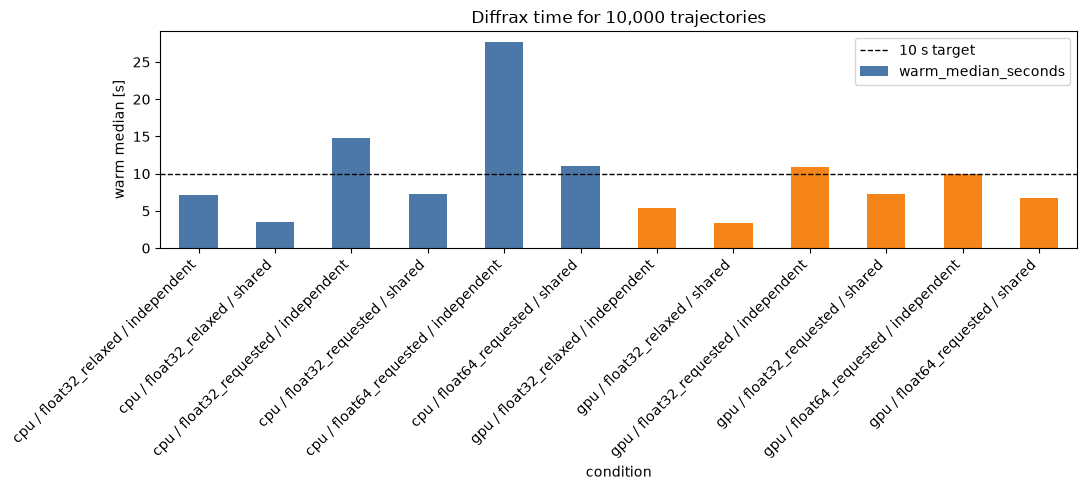

In [8]:
plot_data = timings.copy()
plot_data["condition"] = (
    plot_data["device"] + " / " + plot_data["configuration"] + " / " + plot_data["batch_mode"]
)
colors = plot_data["device"].map({"cpu": "#4C78A8", "gpu": "#F58518"})
ax = plot_data.plot.bar(
    x="condition",
    y="warm_median_seconds",
    color=colors,
    legend=False,
    ylabel="warm median [s]",
    title="Diffrax time for 10,000 trajectories",
    figsize=(11, 5),
)
ax.axhline(10.0, color="black", linestyle="--", linewidth=1, label="10 s target")
ax.legend()
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
controller = timings[
    [
        "device",
        "configuration",
        "batch_mode",
        "median_steps",
        "median_accepted_steps",
        "median_rejected_steps",
        "max_rejected_steps",
    ]
].copy()
display(controller)

,device,configuration,batch_mode,median_steps,median_accepted_steps,median_rejected_steps,max_rejected_steps
0,cpu,float32_relaxed,independent,4180.0,2994.0,1185.0,1238
1,cpu,float32_relaxed,shared,2786.0,2786.0,0.0,0
2,cpu,float32_requested,independent,8609.0,6197.0,2405.0,2538
3,cpu,float32_requested,shared,6007.0,6007.0,0.0,0
4,cpu,float64_requested,independent,8338.0,6108.0,2227.0,2267
5,cpu,float64_requested,shared,6002.0,6002.0,0.0,0
6,gpu,float32_relaxed,independent,4180.0,2994.0,1185.0,1241
7,gpu,float32_relaxed,shared,2786.0,2786.0,0.0,0
8,gpu,float32_requested,independent,8609.0,6197.0,2404.0,2543
9,gpu,float32_requested,shared,6007.0,6007.0,0.0,0


### Numerical agreement

Feature errors are measured against the tight, independently stepped float64
CPU reference. Because phase error grows over this long periodic integration,
the report compares the steady-state statistics consumed by the classifier
rather than pointwise states.


In [10]:
accuracy = pd.DataFrame(results["accuracy"])
display(
    accuracy[
        [
            "device",
            "configuration",
            "dtype",
            "batch_mode",
            "label_agreement",
            "label_mismatches",
            "median_absolute_feature_error",
            "p95_absolute_feature_error",
            "max_absolute_feature_error",
        ]
    ]
)

,device,configuration,dtype,batch_mode,label_agreement,label_mismatches,median_absolute_feature_error,p95_absolute_feature_error,max_absolute_feature_error
0,cpu,float32_relaxed,float32,independent,1.0,0,0.000763,0.002431,0.081148
1,cpu,float32_relaxed,float32,shared,1.0,0,0.000740,0.002386,0.005248
2,cpu,float32_requested,float32,independent,1.0,0,0.000048,0.000266,0.000684
3,cpu,float32_requested,float32,shared,1.0,0,0.000020,0.000150,0.000381
4,cpu,float64_requested,float64,independent,1.0,0,0.000003,0.000017,0.000186
5,cpu,float64_requested,float64,shared,1.0,0,0.000004,0.000019,0.000066
6,gpu,float32_relaxed,float32,independent,1.0,0,0.000761,0.002420,0.075159
7,gpu,float32_relaxed,float32,shared,1.0,0,0.000738,0.002385,0.005319
8,gpu,float32_requested,float32,independent,1.0,0,0.000048,0.000270,0.000674
9,gpu,float32_requested,float32,shared,1.0,0,0.000020,0.000148,0.000425


### Batching-policy and device sensitivity

The first table isolates the controller policy on each device. The second
holds numerical configuration and policy fixed while comparing CPU with GPU.


In [11]:
batching_agreement = pd.DataFrame(results["batching_agreements"])
device_agreement = pd.DataFrame(results["device_agreements"])
pairwise_columns = [
    "device",
    "configuration",
    "batch_mode",
    "label_agreement",
    "label_mismatches",
    "median_absolute_feature_difference",
    "p95_absolute_feature_difference",
    "max_absolute_feature_difference",
]
display(batching_agreement[pairwise_columns])
display(device_agreement[pairwise_columns])

,device,configuration,batch_mode,label_agreement,label_mismatches,median_absolute_feature_difference,p95_absolute_feature_difference,max_absolute_feature_difference
0,cpu,float32_relaxed,independent_vs_shared,1.0,0,0.000056,0.000370,0.081884
1,gpu,float32_relaxed,independent_vs_shared,1.0,0,0.000055,0.000369,0.076129
2,cpu,float32_requested,independent_vs_shared,1.0,0,0.000056,0.000305,0.000752
3,gpu,float32_requested,independent_vs_shared,1.0,0,0.000056,0.000306,0.000703
4,cpu,float64_requested,independent_vs_shared,1.0,0,0.000002,0.000017,0.000196
5,gpu,float64_requested,independent_vs_shared,1.0,0,0.000002,0.000017,0.000192


,device,configuration,batch_mode,label_agreement,label_mismatches,median_absolute_feature_difference,p95_absolute_feature_difference,max_absolute_feature_difference
0,cpu_vs_gpu,float32_relaxed,independent,1.0,0,5.626678e-05,4.034042e-04,8.189106e-02
1,cpu_vs_gpu,float32_relaxed,shared,1.0,0,2.717972e-05,2.560616e-04,8.068085e-04
2,cpu_vs_gpu,float32_requested,independent,1.0,0,3.711879e-05,2.794266e-04,7.395744e-04
3,cpu_vs_gpu,float32_requested,shared,1.0,0,2.145767e-05,1.850128e-04,5.030632e-04
4,cpu_vs_gpu,float64_requested,independent,1.0,0,2.523001e-07,3.838458e-06,8.479967e-06
5,cpu_vs_gpu,float64_requested,shared,1.0,0,7.283063e-14,5.897505e-13,1.856293e-12


In [12]:
warm_target = timings["warm_median_seconds"] < 10
fastest_index = timings["warm_median_seconds"].idxmin()
fastest = timings.loc[fastest_index]
requested_x32 = accuracy[accuracy["configuration"] == "float32_requested"]
requested_x64 = accuracy[accuracy["configuration"] == "float64_requested"]
median_error_ratio = (
    requested_x32["median_absolute_feature_error"].median()
    / requested_x64["median_absolute_feature_error"].median()
)

print(f"Warm conditions below 10 seconds: {warm_target.sum()} / {len(warm_target)}")
print(
    "Fastest condition: "
    f"{fastest['device']} / {fastest['configuration']} / {fastest['batch_mode']} "
    f"at {fastest['warm_median_seconds']:.3f} s"
)
print(f"Worst float32 rtol=1e-8 label agreement: {requested_x32['label_agreement'].min():.4%}")
print(f"Worst float64 rtol=1e-8 label agreement: {requested_x64['label_agreement'].min():.4%}")
print(f"Median feature-error ratio, float32 versus float64 at rtol=1e-8: {median_error_ratio:.1f}x")
print(f"Worst CPU/GPU label agreement: {device_agreement['label_agreement'].min():.4%}")

Warm conditions below 10 seconds: 8 / 12
Fastest condition: gpu / float32_relaxed / shared at 3.347 s
Worst float32 rtol=1e-8 label agreement: 100.0000%
Worst float64 rtol=1e-8 label agreement: 100.0000%
Median feature-error ratio, float32 versus float64 at rtol=1e-8: 9.6x
Worst CPU/GPU label agreement: 100.0000%


## Discussion

The measurements separate three effects that were previously mixed across
CPU- and GPU-specific reports. Warm execution answers the repeated-chunk use
case, while compilation plus first execution describes a new shape. The
speedup tables show whether either device or controller policy has a consistent
advantage; neither comparison should be inferred from one configuration.

Shared stepping changes more than controller overhead. Diffrax applies its
error norm to the complete batched state, whereas the independently stepped
solve applies it to each two-component trajectory. Consequently, errors from
individual difficult trajectories can be diluted in the batch-wide norm. The
accepted and rejected step counts expose that change directly and must be read
alongside the feature and label comparisons.

Tolerance and dtype must be interpreted together. A requested relative
tolerance below float32 machine precision cannot create eight reliable decimal
digits; at best it changes the controller's behavior under an accuracy floor
set by the representation. The float64 comparison shows whether the same
requested tolerance materially changes the basin labels and feature statistics.

### Limitations

This is one ODE, one initial-condition distribution, one batch size, and one
hardware pair. The one-million estimate assumes 100 identically shaped warm
chunks and therefore does not include sampling, host-side orchestration, or
downstream clustering. Shared stepping also couples controller decisions across
the batch, so its numerical agreement here does not establish equivalence for
systems with rare stiff or escaping trajectories.
